# Lollipop Chart

**Family:** Ranking &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Ranking:* Use when an item's position in an ordered list matters more than its absolute value.

## Design purpose

A thin stem with a dot at the value. It encodes the same thing as a bar but with far less ink, so long rankings look lighter and the endpoints stand out.

## When to use

- Show rankings with many items (15–40) where bars would form a heavy block
- Rank items where the endpoint matters more than the filled area of a bar

## Avoid when

- The axis does not start at zero (the stem length then misleads)
- There are very few categories (a bar chart is more familiar)

## Alternatives

- Ordered bar chart
- Cleveland dot plot

## Design tips

- Start the stems at zero, as with bars; if the values are close and far from zero, use a dot plot instead
- Sort by value so the ranking reads top to bottom
- Keep the stems thin and the dots large enough to carry the value

## Example

Average customer rating (out of 100) for 20 coffee shops, simulated data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(9)
shops = [f"Café {n}" for n in ["Aroma", "Bean", "Crema", "Dolce", "Espresso", "Filtro", "Grind",
                                "Hazel", "Iris", "Java", "Kona", "Latte", "Mocha", "Nero",
                                "Oat", "Pour", "Quill", "Roast", "Sip", "Tamp"]]
df = pd.DataFrame({"shop": shops, "score": rng.normal(78, 7, 20).clip(55, 97).round(1)})
df = df.sort_values("score").reset_index(drop=True)
df.tail()

,shop,score
15,Café Espresso,86.0
16,Café Roast,87.7
17,Café Latte,87.9
18,Café Tamp,89.0
19,Café Nero,95.7


### Plot

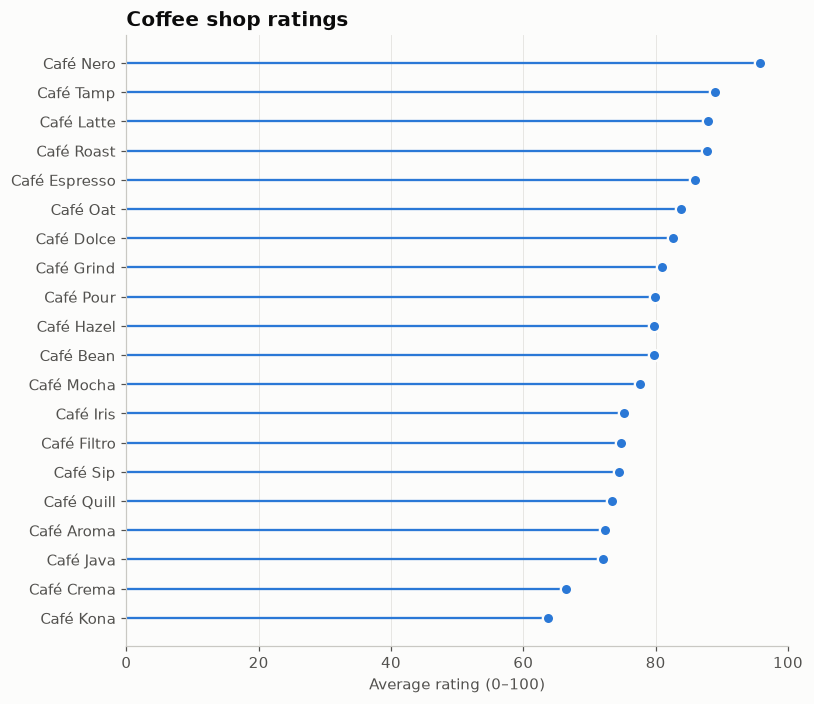

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.hlines(df.index, 0, df["score"], color=PALETTE[0], linewidth=1.5)
ax.scatter(df["score"], df.index, s=55, color=PALETTE[0], zorder=3,
           edgecolor="#fcfcfb", linewidth=1.5)
ax.set_yticks(df.index, df["shop"])
ax.set_xlim(0, 100)
ax.set_xlabel("Average rating (0–100)")
ax.set_title("Coffee shop ratings")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Shops are sorted from the highest rating (top) to the lowest. Café Nero leads with about 96; most shops sit between 72 and 90, and Café Crema and Café Kona trail below 67.

---
Standalone script: [`lollipop_ranking.py`](lollipop_ranking.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)